# Satellite experiments (Group 4)

This notebook tests improvements to the shadow index of `Satellite_Group4.ipynb`. It does not change that
notebook. The plan:

1. Rebuild the baseline with the same steps and check that we get the same numbers.
2. Change **one** thing per experiment and keep everything else as in the baseline.
3. Collect all results in one table at the end.

Each rule is written down in a markdown cell **before** the code that shows its result.

**Cache.** Every Sentinel-2 window is downloaded once and saved in `data/cache/s2/` as one `.npy` file
(the RGB pixels) plus one `.json` file (date, tile, sun, cloud cover, ...). Files are named by image id, for
example `S2B_14SQE_20180120_0_L2A.npy`, not by date, because one date can have up to four images (two tiles,
and for many days two processing versions of each tile). The image search and the OpenStreetMap answer are
cached too. The first run downloads about 650 windows (about 1 hour, 4 GB); after that everything runs
offline in a few minutes.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import requests
import statsmodels.formula.api as smf
from affine import Affine
from rasterio.transform import rowcol
from rasterio.warp import transform
from rasterio.windows import Window

sys.path.insert(0, "pipeline")  # Claas's helpers live in project/pipeline/
import viz

CUSHING = (35.985, -96.767)  # town centre, used for the image search
CENTRE = (35.967, -96.750)   # centre of our 14 km window
HALF_KM = 7
PIXEL_M = 10                 # Sentinel-2 true colour pixels are 10 m

# Baseline settings, the same as in Satellite_Group4.ipynb
TANK_HEIGHT = 15    # metres
DARK = 0.4          # a pixel darker than this counts as shadow
MAX_BLACK = 0.01    # skip a window with more than 1% black (no data) pixels
CLOUD_RATIO = 0.7   # a ratio at or above this means clouds: dropped in the test

CACHE = Path("data/cache")
(CACHE / "s2").mkdir(parents=True, exist_ok=True)
(CACHE / "scl").mkdir(parents=True, exist_ok=True)

## 1. Cached data

Three small helpers. Each one downloads the first time and reads the cache afterwards.

In [2]:
def search_items():
    """All Sentinel-2 images over Cushing, 2017-2024, as STAC items (searched once)."""
    path = CACHE / "s2_items_2017_2024.json"
    if not path.exists():
        items = []
        for year in range(2017, 2025):  # one search per year: a search returns at most 200 images
            items += viz.s2_search(*CUSHING, f"{year}-01-01", f"{year}-12-31")
        path.write_text(json.dumps(items))
    return json.loads(path.read_text())


def load_chip(item):
    """RGB window (1400 x 1400 x 3) around CENTRE, downloaded once and then read from the cache."""
    path = CACHE / "s2" / f"{item['id']}.npy"
    if not path.exists():
        chip = viz.s2_chip(item, *CENTRE, half_km=HALF_KM)
        props = item["properties"]
        meta = {"id": item["id"], "datetime": props["datetime"],
                "tile": props["mgrs:grid_square"],
                "processing_baseline": props["s2:processing_baseline"],
                "cloud_cover": props["eo:cloud_cover"],
                "sun_azimuth": props["view:sun_azimuth"],
                "sun_elevation": props["view:sun_elevation"],
                "no_data": float((chip.sum(axis=2) == 0).mean()),
                "href": item["assets"]["visual"]["href"],
                "centre": CENTRE, "half_km": HALF_KM}
        np.save(path, chip)
        path.with_suffix(".json").write_text(json.dumps(meta, indent=1))
    return np.load(path)


def osm_tanks():
    """Storage tanks in our window from OpenStreetMap (Overpass), fetched once."""
    path = CACHE / "osm_tanks.json"
    if not path.exists():
        box = (35.904, -96.828, 36.030, -96.672)  # south, west, north, east
        query = f'[out:json];\nnwr["man_made"="storage_tank"]{box};\nout geom;'
        answer = requests.post("https://overpass-api.de/api/interpreter", data={"data": query},
                               headers={"User-Agent": "Bocconi student project"}, timeout=180)
        answer.raise_for_status()
        path.write_text(answer.text)
    return json.loads(path.read_text())["elements"]

Short helpers to read an image's properties.

In [3]:
def date_of(item):
    """Acquisition date 'YYYY-MM-DD'."""
    return item["properties"]["datetime"][:10]


def cloud_of(item):
    """Cloud cover of the whole 110 km tile, in percent."""
    return item["properties"]["eo:cloud_cover"]


def sun_of(item):
    """Sun elevation in degrees."""
    return item["properties"]["view:sun_elevation"]


def black_share(chip):
    """Share of black (no data) pixels in a window."""
    return (chip.sum(axis=2) == 0).mean()


found = search_items()
# A few images are stored in a requester-pays bucket (s3:// links) that needs a paid AWS account: skip them
items = [item for item in found if item["assets"]["visual"]["href"].startswith("https")]
print("Not freely downloadable, skipped:",
      [item["id"] for item in found if not item["assets"]["visual"]["href"].startswith("https")])

winter = [item for item in items if cloud_of(item) < 5 and sun_of(item) < 45]
print(f"{len(items)} images, {len(winter)} clear with low sun, "
      f"on {len({date_of(item) for item in winter})} different dates")

Not freely downloadable, skipped: ['S2B_14SQE_20200728_0_L2A', 'S2B_14SPE_20200728_0_L2A', 'S2A_14SQE_20200802_0_L2A', 'S2A_14SPE_20200802_0_L2A', 'S2B_14SQE_20200807_0_L2A', 'S2B_14SPE_20200807_0_L2A', 'S2A_14SQE_20200812_0_L2A', 'S2A_14SPE_20200812_0_L2A', 'S2B_14SQE_20201026_0_L2A', 'S2B_14SPE_20201026_0_L2A']
1233 images, 169 clear with low sun, on 69 different dates


## 2. Tank map, as in the baseline

Same steps as `Satellite_Group4.ipynb`: OpenStreetMap outlines, converted to circles in the pixels of our
window; keep tanks that are bright on at least one of nine 2018 dates; drop tanks whose roof is more than 70%
dark on the reference image.

One difference in the code, not in the result: the baseline opens the image file to get the pixel grid. The
grid is also in the image metadata (`proj:transform`), so we read it from there and need no download. Both
tiles over Cushing (14SPE and 14SQE) are in the same UTM zone (EPSG:32614) and share the same 10 m grid, so
one tank map is valid for every image.

In [4]:
def window_origin(item):
    """Pixel grid of an image's tile, and the first (row, column) of our window in it."""
    grid = Affine(*item["assets"]["visual"]["proj:transform"][:6])
    crs = f"EPSG:{item['properties']['proj:epsg']}"
    (x,), (y,) = transform("EPSG:4326", crs, [CENTRE[1]], [CENTRE[0]])
    row0, col0 = rowcol(grid, x, y)
    half = int(HALF_KM * 1000 / PIXEL_M)
    return grid, crs, row0 - half, col0 - half


def tank_circles(tanks, item):
    """Centre (row, column) and radius of each tank outline, in pixels of our window."""
    grid, crs, top, left = window_origin(item)
    centres, radii = [], []
    for tank in tanks:
        points = tank["geometry"][:-1]  # the last point repeats the first
        xs, ys = transform("EPSG:4326", crs, [p["lon"] for p in points], [p["lat"] for p in points])
        cols, rows = ~grid * (np.array(xs), np.array(ys))  # map coordinates to (column, row)
        rows, cols = rows - top, cols - left
        centres.append((rows.mean(), cols.mean()))
        radii.append(np.hypot(rows - rows.mean(), cols - cols.mean()).mean())
    return np.array(centres), np.array(radii)


def tank_brightness(gray, centres, radii):
    """Mean brightness inside each tank circle (0 = black, 1 = white)."""
    values = []
    for (row, col), r in zip(centres, radii):
        r = max(r, 1)  # very small tanks: use at least one pixel
        top, left = int(row - r), int(col - r)
        window = gray[top:int(row + r) + 1, left:int(col + r) + 1]
        rr, cc = np.indices(window.shape)
        inside = np.hypot(rr + top + 0.5 - row, cc + left + 0.5 - col) <= r
        values.append(window[inside].mean())
    return np.array(values)

In [5]:
tanks = osm_tanks()
clear_2018 = [item for item in items if date_of(item)[:4] == "2018" and cloud_of(item) < 5]
reference = next(item for item in clear_2018 if black_share(load_chip(item)) < 0.01)
print(f"{len(tanks)} tanks in OpenStreetMap, reference image {reference['id']}")

centres, radii = tank_circles(tanks, reference)
print(f"Radius: median {np.median(radii) * 10:.0f} m, "
      f"smallest {radii.min() * 10:.0f} m, largest {radii.max() * 10:.0f} m")

brightness = np.array([tank_brightness(load_chip(item).mean(axis=2) / 255, centres, radii)
                       for item in clear_2018[::6]])  # every 6th clear image of 2018
built = brightness.max(axis=0) > 0.6  # bright on at least one date
centres, radii = centres[built], radii[built]
print(f"{built.sum()} of {len(built)} tanks existed in 2018")

415 tanks in OpenStreetMap, reference image S2B_14SPE_20180120_0_L2A
Radius: median 31 m, smallest 9 m, largest 43 m


401 of 415 tanks existed in 2018


## 3. Shadow index, as in the baseline

`shadow_counts` is the baseline function with two small additions, both off by default:
the threshold `dark` is a parameter (experiment 3), and the shadow length can be one number per tank
(experiment 4).

In [6]:
def shadow_counts(gray, centres, radii, L_px, d_row, d_col, dark=DARK):
    """Dark pixels on the roofs and in the ground shadows, summed over all tanks.

    L_px is the shadow length in pixels: one number for all tanks, or one number per tank.
    """
    L_px = np.broadcast_to(L_px, radii.shape)
    roof_dark, ground_dark = 0, 0
    per_tank = []  # dark roof pixels of each tank
    for (row, col), r, L in zip(centres, radii, L_px):
        reach = int(r + L) + 2
        top, left = int(row) - reach, int(col) - reach
        window = gray[top:int(row) + reach, left:int(col) + reach]
        rr, cc = np.indices(window.shape)
        y = rr + top + 0.5 - row  # pixel centre, relative to the tank centre
        x = cc + left + 0.5 - col

        on_roof = np.hypot(y, x) <= r
        t = np.clip(y * d_row + x * d_col, 0, L)  # how far along the shadow direction
        swept = np.hypot(y - t * d_row, x - t * d_col) <= r
        in_ground_shadow = swept & ~on_roof

        is_dark = window < dark
        roof_dark += (is_dark & on_roof).sum()
        ground_dark += (is_dark & in_ground_shadow).sum()
        per_tank.append((is_dark & on_roof).sum())
    return roof_dark, ground_dark, per_tank


def shadow_geometry(item, height=TANK_HEIGHT):
    """Shadow length in pixels and its direction (d_row, d_col) from the sun position of an image."""
    elevation = item["properties"]["view:sun_elevation"]
    azimuth = item["properties"]["view:sun_azimuth"]
    L_px = height / np.tan(np.radians(elevation)) / PIXEL_M
    direction = np.radians(azimuth + 180)  # shadows point away from the sun
    return L_px, -np.cos(direction), np.sin(direction)  # rows grow southward

In [7]:
# Drop tanks whose roof is mostly dark on the reference image (permanently dark roofs)
gray_ref = load_chip(reference).mean(axis=2) / 255
_, _, per_tank = shadow_counts(gray_ref, centres, radii, *shadow_geometry(reference))
roof_pixels = np.array([max(np.pi * r ** 2, 1) for r in radii])
keep = np.array(per_tank) / roof_pixels < 0.7
CENTRES, RADII = centres[keep], radii[keep]
print(f"Dropped {(~keep).sum()} dark roofed tanks, keeping {len(CENTRES)}")

Dropped 3 dark roofed tanks, keeping 398


`measure` turns one image into one row of the index. Every experiment below only changes which images go
in, or one argument of `measure`.

In [8]:
def measure(item, chip, centres=CENTRES, radii=RADII, height=TANK_HEIGHT, dark=DARK):
    """One row of the index: dark roof pixels / dark ground shadow pixels for one image."""
    L_px, d_row, d_col = shadow_geometry(item, height)
    gray = chip.mean(axis=2) / 255
    roof, ground, _ = shadow_counts(gray, centres, radii, L_px, d_row, d_col, dark)
    return {"date": date_of(item), "image": item["id"], "sun_elevation": sun_of(item),
            "roof_dark": roof, "ground_dark": ground, "ratio": roof / ground}


def to_frame(rows):
    """Rows of the index as a DataFrame indexed by date, in time order."""
    index = pd.DataFrame(rows)
    index["date"] = pd.to_datetime(index["date"])
    return index.set_index("date").sort_index()


def first_tiles(images):
    """Baseline rule: for each day, the first image whose window has at most 1% black pixels."""
    chosen, dates = [], set()
    for item in images:
        if date_of(item) in dates:
            continue  # this day is already measured
        if black_share(load_chip(item)) > MAX_BLACK:
            continue  # tile edge cuts our window: try the next image of the same day
        chosen.append(item)
        dates.add(date_of(item))
    return chosen


def build_index(chosen, **options):
    """Measure each chosen image. `options` are passed on to `measure`, for example height=12."""
    return to_frame([measure(item, load_chip(item), **options) for item in chosen])

## 4. The test, as in the baseline

EIA weekly Cushing stocks, closest weekly report to each image. Drop images with ratio ≥ 0.7 (clouds),
then the correlation and the OLS `ratio ~ stocks + sun_elevation` with HAC errors (3 lags).

In [9]:
table = pd.read_excel("data/raw/eia_cushing_w.xls", sheet_name="Data 1", skiprows=2)
cushing = table.set_index(table.columns[0]).iloc[:, 0].astype(float) / 1000  # million barrels


def add_stocks(index):
    """Add the closest weekly EIA Cushing stock (million barrels) to each date."""
    index = index.copy()
    index["stocks"] = cushing.reindex(index.index, method="nearest").values
    return index


FORMULA = "ratio ~ stocks + sun_elevation"


def fit(clean, name, dates, formula=FORMULA):
    """Correlation and OLS with HAC errors (3 lags) on cloud free data, as one row of the results."""
    model = smf.ols(formula, data=clean).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    return {"experiment": name, "dates": dates, "clean dates": len(clean),
            "correlation": clean["ratio"].corr(clean["stocks"]),
            "stocks coef": model.params["stocks"], "HAC z": model.tvalues["stocks"],
            "sun z": model.tvalues["sun_elevation"]}


def evaluate(index, name):
    """Add stocks, drop cloud images (ratio >= 0.7) and fit."""
    data = add_stocks(index)
    clean = data[data["ratio"] < CLOUD_RATIO]
    return fit(clean, name, dates=len(data))


results = []  # one row per experiment, shown at the end


def report(row):
    """Store one result row for the final table and print it."""
    results.append(row)
    print(f"{row['experiment']}: {row['dates']} dates ({row['clean dates']} without clouds), "
          f"correlation {row['correlation']:.2f}, stocks coef {row['stocks coef']:.4f}, "
          f"HAC z {row['HAC z']:.1f}, sun z {row['sun z']:.1f}")
    return row

## 5. Baseline reproduction

If these numbers differ from `Satellite_Group4.ipynb` (64 dates, correlation −0.40, coefficient −0.0035,
z = −4.6), we stop here.

In [10]:
base_images = first_tiles(winter)
baseline = build_index(base_images)
report(evaluate(baseline, "0. Baseline"))

saved = pd.read_csv("data/out/shadow_index.csv", index_col="date", parse_dates=True)
same = (saved[["roof_dark", "ground_dark"]].values == baseline[["roof_dark", "ground_dark"]].values).all()
print("Identical to data/out/shadow_index.csv, date by date:", same and (saved.index == baseline.index).all())

0. Baseline: 64 dates (62 without clouds), correlation -0.40, stocks coef -0.0035, HAC z -4.6, sun z -1.6
Identical to data/out/shadow_index.csv, date by date: True


## 6. Experiments

All rules below were fixed before running any of them. Each experiment changes one thing; everything else
(398 tanks, 15 m, dark < 0.4, tile cloud < 5%, sun < 45°, first tile with ≤ 1% black, ratio < 0.7, HAC 3
lags) stays as in the baseline.

### Experiment 1: more dates from tile edges

Fact found before the test: the 169 baseline images cover only **69** dates, not 169. The "duplicates" are
mostly the same picture twice: the second tile of the same day, or a second processing version of the same
tile. The baseline already tries the next image of a day when the first is cut by a tile edge, so only
**5 dates** are lost. On those 5 dates only tile 14SQE passed the cloud filter, and its black strip covers
columns 0 to 407 of our window, while all tanks lie in columns 556 to 1024.

* **1a, best tile.** For each day, take the image with the fewest black pixels (the rule of
  `viz.s2_best_chip`; a tie goes to the more central tile). Keep the 1% rule. We do not call
  `viz.s2_best_chip` itself because it downloads without caching; this is the same rule on cached windows.
  Prediction: no new dates, because on the 5 lost days there is no second tile to choose.
* **1b, black only matters on the tanks.** Baseline tile choice, but skip an image only if a black pixel falls
  within 4 pixels of a tank roof (4 pixels = 40 m covers the longest winter shadow, 15 m / tan 28° = 28 m).

In [11]:
def best_tiles(images):
    """For each day, the image with the fewest black pixels; ties go to the more central tile."""
    chosen = []
    for date in sorted({date_of(item) for item in images}):
        day = [item for item in images if date_of(item) == date]
        day.sort(key=lambda item: -viz.bbox_margin(item, *CENTRE))  # most central first
        blacks = [black_share(load_chip(item)) for item in day]
        best = day[int(np.argmin(blacks))]  # argmin keeps the first one in a tie
        if black_share(load_chip(best)) <= MAX_BLACK:
            chosen.append(best)
    return chosen


report(evaluate(build_index(best_tiles(winter)), "1a. Best tile per day"))

1a. Best tile per day: 64 dates (62 without clouds), correlation -0.38, stocks coef -0.0036, HAC z -4.5, sun z -1.8


{'experiment': '1a. Best tile per day',
 'dates': 64,
 'clean dates': 62,
 'correlation': np.float64(-0.38055335187418887),
 'stocks coef': np.float64(-0.003646170392995955),
 'HAC z': np.float64(-4.49283610532477),
 'sun z': np.float64(-1.7883563840390344)}

In [12]:
rr, cc = np.indices(gray_ref.shape)  # row and column of every pixel of the window


def near_tanks(margin):
    """True for pixels within `margin` pixels of a tank roof."""
    mask = np.zeros(rr.shape, dtype=bool)
    for (row, col), r in zip(CENTRES, RADII):
        mask |= np.hypot(rr + 0.5 - row, cc + 0.5 - col) <= r + margin
    return mask


tank_area = near_tanks(4)


def first_tiles_tank_check(images):
    """Like `first_tiles`, but skip an image only if black pixels touch the tanks or their shadows."""
    chosen, dates = [], set()
    for item in images:
        if date_of(item) in dates:
            continue
        black = load_chip(item).sum(axis=2) == 0
        if (black & tank_area).any():
            continue
        chosen.append(item)
        dates.add(date_of(item))
    return chosen


report(evaluate(build_index(first_tiles_tank_check(winter)), "1b. Black pixels checked on tanks only"))

1b. Black pixels checked on tanks only: 69 dates (66 without clouds), correlation -0.35, stocks coef -0.0034, HAC z -4.6, sun z -2.1


{'experiment': '1b. Black pixels checked on tanks only',
 'dates': 69,
 'clean dates': 66,
 'correlation': np.float64(-0.35350891313376875),
 'stocks coef': np.float64(-0.0033781374451667297),
 'HAC z': np.float64(-4.565257710161968),
 'sun z': np.float64(-2.113856625379324)}

### Experiment 2: clouds over our window instead of the whole tile

`eo:cloud_cover` is the cloud share of the whole 110 km tile. A tile can be 4% cloudy with the cloud right
over Cushing (2020-11-05, ratio 1.89), or 30% cloudy with Cushing clear. Each Sentinel-2 L2A image comes with
a scene classification layer (SCL, 20 m) that labels every pixel.

**Rule**: among all low sun images (any tile cloud cover), keep those where less than **2%** of the valid
pixels of our window are SCL classes 3 (cloud shadow), 8 (cloud, medium probability), 9 (cloud, high
probability) or 10 (thin cirrus). Why 2% and not 1%: the tank roofs alone are 0.6% of the window, and bright
roofs are sometimes classified as cloud, so 1% could reject clear images for the wrong reason. Everything
else as in the baseline, including the drop of ratios ≥ 0.7.

In [13]:
CLOUD_CLASSES = [3, 8, 9, 10]  # SCL: cloud shadow, cloud medium and high probability, thin cirrus
MAX_LOCAL_CLOUD = 0.02


def load_scl(item):
    """Scene classification (20 m, 700 x 700) of our window, downloaded once and then cached."""
    path = CACHE / "scl" / f"{item['id']}.npy"
    if not path.exists():
        with rasterio.open(item["assets"]["scl"]["href"]) as ds:
            (x,), (y,) = transform("EPSG:4326", ds.crs, [CENTRE[1]], [CENTRE[0]])
            row, col = ds.index(x, y)
            half = int(HALF_KM * 1000 / ds.res[0])
            window = Window(col - half, row - half, 2 * half, 2 * half)
            np.save(path, ds.read(1, window=window, boundless=True, fill_value=0))
    return np.load(path)


def local_cloud(item):
    """Share of the valid pixels of our window classified as cloud, cloud shadow or cirrus."""
    scl = load_scl(item)
    valid = scl[scl > 0]  # 0 = no data
    return np.isin(valid, CLOUD_CLASSES).mean() if valid.size else 1.0


low_sun = [item for item in items if sun_of(item) < 45]
local_clear = [item for item in low_sun if local_cloud(item) < MAX_LOCAL_CLOUD]
print(f"{len(low_sun)} low sun images, {len(local_clear)} with < 2% cloud over our window "
      f"(baseline: {len(winter)} with < 5% cloud over the tile)")
in_both = {item["id"] for item in local_clear} & {item["id"] for item in winter}
print(f"{len(in_both)} images pass both filters")

local = build_index(first_tiles(local_clear))
report(evaluate(local, "2. Local cloud check (SCL < 2%)"))
print(f"Ratios >= 0.7 left after the local check: {(local['ratio'] >= CLOUD_RATIO).sum()}")

440 low sun images, 200 with < 2% cloud over our window (baseline: 169 with < 5% cloud over the tile)
153 images pass both filters


2. Local cloud check (SCL < 2%): 76 dates (73 without clouds), correlation -0.41, stocks coef -0.0035, HAC z -3.6, sun z -2.1
Ratios >= 0.7 left after the local check: 3


### Experiment 3: a dark threshold relative to each image

The same 0.4 for every image assumes the same brightness scale in every image. Haze, the season and changes
in Sentinel-2 processing move all pixels up or down.

**3a, rule**: scale the threshold by the median brightness of all roof pixels:
`dark = 0.4 × median roof brightness of this image / median roof brightness of the reference image`.
On the reference image (2018-01-20) this is exactly 0.4. The median roof pixel is a lit part of a roof (only
about 6% of roof pixels are dark), so it measures how bright the image is, not how full the tanks are.

Not chosen: a percentile of the roof pixels as the threshold. That would fix the share of dark roof pixels in
every image and remove the very signal we measure.

In [14]:
roof_mask = near_tanks(0)  # pixels on a roof
ref_median = np.median(gray_ref[roof_mask])
print(f"Median roof brightness on the reference image: {ref_median:.3f}")

rows = []
for item in base_images:
    chip = load_chip(item)
    dark = DARK * np.median((chip.mean(axis=2) / 255)[roof_mask]) / ref_median
    rows.append(measure(item, chip, dark=dark) | {"dark": dark})
relative = to_frame(rows)
print(f"Threshold per image: from {relative['dark'].min():.2f} to {relative['dark'].max():.2f}")
report(evaluate(relative, "3a. Threshold relative to roof brightness"))

Median roof brightness on the reference image: 1.000


Threshold per image: from 0.40 to 0.40
3a. Threshold relative to roof brightness: 64 dates (62 without clouds), correlation -0.40, stocks coef -0.0035, HAC z -4.6, sun z -1.6


{'experiment': '3a. Threshold relative to roof brightness',
 'dates': 64,
 'clean dates': 62,
 'correlation': np.float64(-0.40331461177113714),
 'stocks coef': np.float64(-0.003525346170107315),
 'HAC z': np.float64(-4.638229499465013),
 'sun z': np.float64(-1.5730304373728146)}

**What happened**: the median roof pixel is 1.0, pure white. The true colour product clips bright surfaces
at 255, so roofs cannot tell us how bright an image is, and the threshold stays 0.4 everywhere.

**3b, rule fixed after seeing the clipping and before seeing any correlation**: scale by the median
brightness of the whole window instead (mostly fields and roads, which are not clipped):
`dark = 0.4 × median window brightness / median window brightness of the reference image`.
Risk known in advance: fields change colour with the season, which can move the threshold for reasons
unrelated to light.

In [15]:
ref_window = np.median(gray_ref)
rows = []
for item in base_images:
    chip = load_chip(item)
    dark = DARK * np.median(chip.mean(axis=2) / 255) / ref_window
    rows.append(measure(item, chip, dark=dark) | {"dark": dark})
relative = to_frame(rows)
print(f"Threshold per image: from {relative['dark'].min():.2f} to {relative['dark'].max():.2f}")
report(evaluate(relative, "3b. Threshold relative to window brightness"))

Threshold per image: from 0.25 to 0.46
3b. Threshold relative to window brightness: 64 dates (61 without clouds), correlation -0.28, stocks coef -0.0022, HAC z -3.0, sun z -1.9


{'experiment': '3b. Threshold relative to window brightness',
 'dates': 64,
 'clean dates': 61,
 'correlation': np.float64(-0.28368194874247715),
 'stocks coef': np.float64(-0.002228936072643063),
 'HAC z': np.float64(-3.0322673886382465),
 'sun z': np.float64(-1.9287771552365192)}

### Experiment 4: tank height

**Not possible as planned**: none of the 415 OpenStreetMap tanks has a `height` tag (the only tags are
`man_made`, `building`, and `content` on 2 tanks). So we cannot replace 15 m with real heights.

Instead, a **sensitivity check** (not a candidate to adopt): 12 m and 18 m (±20%) for every tank. If the
result moves a lot, the 15 m assumption matters and is a risk to mention in the presentation.

In [16]:
for height in (12, 18):
    report(evaluate(build_index(base_images, height=height), f"4. Height {height} m (sensitivity)"))

4. Height 12 m (sensitivity): 64 dates (61 without clouds), correlation -0.52, stocks coef -0.0044, HAC z -5.2, sun z -2.0


4. Height 18 m (sensitivity): 64 dates (62 without clouds), correlation -0.39, stocks coef -0.0031, HAC z -4.3, sun z -1.7


### Experiment 5: summer images

**Rule**: sun elevation limit 60° and then 70° instead of 45°, everything else as in the baseline. We report
the pooled result, and the high sun part (sun ≥ 45°, "summer") on its own. The low sun part is exactly the
baseline, so it is not repeated.

Prediction: at 60° a 15 m tank casts a 9 m shadow (0.9 pixels), at 70° only 5 m (0.5 pixels), so the ground
crescent is tiny and the summer ratio should be noisy.

In [17]:
for limit in (60, 70):
    images = [item for item in items if cloud_of(item) < 5 and sun_of(item) < limit]
    index = build_index(first_tiles(images))
    report(evaluate(index, f"5. Sun < {limit}, all"))
    report(evaluate(index[index["sun_elevation"] >= 45], f"5. Sun < {limit}, summer part (≥ 45)"))
    print(f"   images with fewer than 50 dark ground pixels: {(index['ground_dark'] < 50).sum()}")

5. Sun < 60, all: 105 dates (103 without clouds), correlation -0.14, stocks coef -0.0020, HAC z -2.0, sun z -5.9
5. Sun < 60, summer part (≥ 45): 41 dates (41 without clouds), correlation 0.17, stocks coef 0.0014, HAC z 1.0, sun z -1.4
   images with fewer than 50 dark ground pixels: 0


/var/folders/sx/8tb9fmr10_x563b6dqnyy94w0000gn/T/ipykernel_61155/1683827367.py:7: RuntimeWarning: invalid value encountered in scalar divide
  "roof_dark": roof, "ground_dark": ground, "ratio": roof / ground}


5. Sun < 70, all: 138 dates (133 without clouds), correlation -0.10, stocks coef -0.0010, HAC z -1.1, sun z -4.5
5. Sun < 70, summer part (≥ 45): 74 dates (71 without clouds), correlation 0.13, stocks coef 0.0015, HAC z 1.1, sun z -0.6
   images with fewer than 50 dark ground pixels: 15


### Experiment 6: misaligned circles

The OpenStreetMap outlines and the Sentinel-2 pixels may be off by a fraction of a pixel. **Rule**: shift
all circles by half a pixel (5 m) north, south, east and west, and see how much the index moves. This is a
robustness check, not a candidate.

In [18]:
for name, (d_row, d_col) in {"south": (0.5, 0), "north": (-0.5, 0),
                             "east": (0, 0.5), "west": (0, -0.5)}.items():
    shifted = build_index(base_images, centres=CENTRES + [d_row, d_col])
    change = (shifted["ratio"] / baseline["ratio"] - 1).abs().median()
    report(evaluate(shifted, f"6. Circles 5 m {name}"))
    print(f"   median change of the ratio {change:.0%}, "
          f"correlation with the baseline index {shifted['ratio'].corr(baseline['ratio']):.2f}")

6. Circles 5 m south: 64 dates (63 without clouds), correlation -0.72, stocks coef -0.0058, HAC z -9.4, sun z -4.0
   median change of the ratio 30%, correlation with the baseline index 0.79


6. Circles 5 m north: 64 dates (58 without clouds), correlation -0.10, stocks coef -0.0012, HAC z -0.7, sun z -1.3
   median change of the ratio 51%, correlation with the baseline index 0.93


6. Circles 5 m east: 64 dates (62 without clouds), correlation -0.56, stocks coef -0.0046, HAC z -7.3, sun z -3.0
   median change of the ratio 12%, correlation with the baseline index 0.97


6. Circles 5 m west: 64 dates (60 without clouds), correlation -0.25, stocks coef -0.0019, HAC z -1.7, sun z -1.3
   median change of the ratio 21%, correlation with the baseline index 0.98


### Experiment 7: changes instead of levels

Stocks fell from about 60 to about 25 million barrels over 2017-2024. If the ratio also drifts up for another
reason (new processing, ageing roofs, tanks added), the levels correlate even without a real link.

* **7a, changes.** Between consecutive cloud free dates at most 30 days apart (so within one winter):
  correlate the change in the ratio with the change in stocks; regress the change in the ratio on the
  change in stocks and the change in sun elevation, HAC 3 lags. 30 days was fixed before looking: it keeps
  pairs inside one season, while 5 to 10 days would leave almost no change in stocks.
* **7b, within each winter.** Levels, but with one dummy per winter (October to March, named by its
  January). Only the variation inside each winter is used, so trends across years cannot drive it.
  The correlation reported is the one within winters (both series minus their winter mean).

In [19]:
data = add_stocks(baseline)
clean = data[data["ratio"] < CLOUD_RATIO]

changes = clean[["ratio", "stocks", "sun_elevation"]].diff()
gap_days = clean.index.to_series().diff().dt.days
pairs = changes[gap_days <= 30]
report(fit(pairs, "7a. Changes (pairs ≤ 30 days apart)", dates=len(pairs)))
print(f"   stocks change between paired dates: median {pairs['stocks'].abs().median():.1f} "
      f"million barrels")

7a. Changes (pairs ≤ 30 days apart): 48 dates (48 without clouds), correlation 0.19, stocks coef 0.0121, HAC z 1.4, sun z -1.4
   stocks change between paired dates: median 1.2 million barrels


In [20]:
clean = clean.assign(winter=clean.index.year + (clean.index.month >= 7))  # Oct 2017 -> winter 2018
within = clean[["ratio", "stocks"]] - clean.groupby("winter")[["ratio", "stocks"]].transform("mean")
row = fit(clean, "7b. Within each winter (winter dummies)", dates=len(clean),
          formula=FORMULA + " + C(winter)")
row["correlation"] = within["ratio"].corr(within["stocks"])
report(row)

7b. Within each winter (winter dummies): 62 dates (62 without clouds), correlation -0.27, stocks coef -0.0053, HAC z -2.5, sun z -2.5


{'experiment': '7b. Within each winter (winter dummies)',
 'dates': 62,
 'clean dates': 62,
 'correlation': np.float64(-0.26670128575240726),
 'stocks coef': np.float64(-0.005310352558074737),
 'HAC z': np.float64(-2.500878763771979),
 'sun z': np.float64(-2.524135826445742)}

### Experiment 8 (our own): one processing version per image

Fact found before the test: for 45 of the 124 day-and-tile pairs the catalogue has two versions, Element 84's
early processing (00.01, 2.xx) and ESA's later reprocessing (05.00). The old version has the earlier time
stamp, so the baseline always takes it. As a result 2017-2019 come only from the old chains and 2022-2024
only from the new ones (04.00 and later). If the chains render brightness differently, the ratio can jump
between years for a reason unrelated to oil, and this jump lines up with the fall in stocks.

**Rule**: for each day and tile keep only the version with the newest processing baseline, then the baseline
rules. Prediction: if the result came from mixing chains, it should weaken.

In [21]:
def processing(item):
    """Processing baseline as a number, for example 5.0 for '05.00'."""
    return float(item["properties"]["s2:processing_baseline"])


def newest_versions(images):
    """Keep, for each day and tile, only the image with the newest processing baseline."""
    newest = {}
    for item in images:
        key = (date_of(item), item["properties"]["mgrs:grid_square"])
        if key not in newest or processing(item) > processing(newest[key]):
            newest[key] = item
    return [item for item in images if item is newest[(date_of(item), item["properties"]["mgrs:grid_square"])]]


newest = build_index(first_tiles(newest_versions(winter)))
report(evaluate(newest, "8. Newest processing version"))
changed = (newest["image"] != baseline["image"].reindex(newest.index)).sum()
print(f"   {changed} of {len(newest)} dates now use a different image")

8. Newest processing version: 63 dates (62 without clouds), correlation -0.49, stocks coef -0.0041, HAC z -5.9, sun z -3.5
   8 of 63 dates now use a different image


### Experiment 9 (our own): line up each image with the reference image

Experiment 6 shows that half a pixel moves the index a lot. Sentinel-2 images are not always placed
exactly on the ground: the error is a few metres and changes from date to date (ESA improved it in later
processing versions, which may be why experiment 8 helps). A different error on each date adds noise to the
index.

We must not pick "the shift that gives the best correlation": that would be tuning on the result. Instead we
measure each image's shift against the reference image, using only the pictures (no EIA data).

**Rule**: `phase_cross_correlation` from scikit-image compares each image with the reference image over the
box that holds all tanks (plus 20 pixels), to 0.1 pixel. We move the circles by the measured shift. If a
shift is larger than 2 pixels in either direction we treat it as a failed match and keep the baseline circles.
Everything else as in the baseline. The reference image itself keeps shift 0, so a constant offset between
OpenStreetMap and the reference image is not corrected here.

In [22]:
from skimage.registration import phase_cross_correlation

top, left = (CENTRES.min(axis=0) - 20).astype(int)
bottom, right = (CENTRES.max(axis=0) + 20).astype(int)
FARMS = (slice(top, bottom), slice(left, right))  # box around all tanks


def image_shift(chip):
    """Shift (rows, columns) of this image against the reference image, to 0.1 pixel."""
    gray = chip.mean(axis=2) / 255
    shift, _, _ = phase_cross_correlation(gray_ref[FARMS], gray[FARMS], upsample_factor=10)
    return -shift  # the function returns the shift that undoes the movement, so we flip it


rows = []
for item in base_images:
    chip = load_chip(item)
    shift = image_shift(chip)
    if np.abs(shift).max() > 2:
        shift = np.zeros(2)  # failed match: keep the baseline circles
    rows.append(measure(item, chip, centres=CENTRES + shift)
                | {"shift_rows": shift[0], "shift_cols": shift[1]})
aligned = to_frame(rows)
report(evaluate(aligned, "9. Each image lined up with the reference"))

aligned["version"] = [item["properties"]["s2:processing_baseline"] for item in base_images]
aligned["shift_m"] = np.hypot(aligned["shift_rows"], aligned["shift_cols"]) * PIXEL_M
print(aligned.groupby("version")["shift_m"].describe()[["count", "mean", "max"]].round(1))

9. Each image lined up with the reference: 64 dates (64 without clouds), correlation -0.64, stocks coef -0.0036, HAC z -5.9, sun z -4.7
         count  mean   max
version                   
00.01     10.0   4.7  14.2
02.13      5.0   4.0  11.4
02.14      2.0  10.2  17.3
03.01      1.0   2.0   2.0
04.00      9.0   3.0   4.5
05.00     12.0   3.8   6.4
05.09     13.0   3.5  10.0
05.10      5.0   3.8   6.1
05.11      7.0   2.8   5.1


The two dates the baseline drops as clouds (2020-11-05 with ratio 1.89 and 2023-11-10 with 0.95) now have
ratios below 0.7, so they enter the test. Lining up a cloudy image with a clear one is unreliable, so this
may be the wrong reason for a better fit. Check: flag clouds before the shift, with the baseline circles.
For these images that means dropping exactly the baseline's two cloud dates.

In [23]:
baseline_clouds = baseline.index[baseline["ratio"] >= CLOUD_RATIO]
print("Ratios on the baseline cloud dates after lining up:", aligned.loc[baseline_clouds, "ratio"].round(2).tolist())
report(evaluate(aligned.drop(baseline_clouds), "9. Lined up, clouds flagged before the shift"))

Ratios on the baseline cloud dates after lining up: [0.07, 0.21]
9. Lined up, clouds flagged before the shift: 62 dates (62 without clouds), correlation -0.62, stocks coef -0.0035, HAC z -5.5, sun z -4.6


{'experiment': '9. Lined up, clouds flagged before the shift',
 'dates': 62,
 'clean dates': 62,
 'correlation': np.float64(-0.6229470518882768),
 'stocks coef': np.float64(-0.003538226754548719),
 'HAC z': np.float64(-5.4639866409478515),
 'sun z': np.float64(-4.600997967353513)}

A risk to check: shadows change with the sun, so the match could partly follow the shadows instead of the
ground. If so, the shift would move with the sun elevation.

In [24]:
print("Correlation of the shift with sun elevation:",
      f"rows {aligned['shift_rows'].corr(aligned['sun_elevation']):.2f},",
      f"columns {aligned['shift_cols'].corr(aligned['sun_elevation']):.2f}")

Correlation of the shift with sun elevation: rows 0.09, columns 0.06


### Experiment 10: the changes we would adopt, together

**This combination is chosen after seeing the results above**, so it is not a clean out-of-sample test.
We pick the changes that are better *for a reason we can explain without the correlation*:

* 1b: images whose tanks are fully visible are kept (5 more dates, same z).
* 8: one processing version, the newest, for every image.
* 9: each image lined up with the reference image.

Not included: 2 (more dates but a lower z, and 3 cloud images still pass the cloud mask), 3b (worse, and the
season risk), 4 (sensitivity only), 5 (no signal in summer).

The two trend checks of experiment 7 are repeated on the combined index, because they are the hardest test.

Lining up a cloudy image moves its circles by a lot (2020-11-05 moves 17 m and its ratio drops from 1.89 to
0.07), so the cloud flag "ratio ≥ 0.7" stops working after the shift. Rule for the combined version: flag
clouds with the **unshifted** circles (exactly as in the baseline), and measure with the shifted circles.

In [25]:
rows = []
for item in first_tiles_tank_check(newest_versions(winter)):
    chip = load_chip(item)
    shift = image_shift(chip)
    if np.abs(shift).max() > 2:
        shift = np.zeros(2)
    cloudy = measure(item, chip)["ratio"] >= CLOUD_RATIO  # cloud flag with the baseline circles
    rows.append(measure(item, chip, centres=CENTRES + shift) | {"cloudy": cloudy})
combined = to_frame(rows)
print("Dates flagged as clouds before lining up:", combined.index[combined["cloudy"]].date.tolist())
report(evaluate(combined, "10. Combined, cloud flag after the shift"))

combined = combined[~combined["cloudy"]]  # from here on: clouds flagged before the shift
report(evaluate(combined, "10. Combined: 1b + 8 + 9"))

Dates flagged as clouds before lining up: [datetime.date(2022, 10, 26), datetime.date(2023, 11, 10)]
10. Combined, cloud flag after the shift: 69 dates (69 without clouds), correlation -0.65, stocks coef -0.0037, HAC z -5.9, sun z -4.9
10. Combined: 1b + 8 + 9: 67 dates (67 without clouds), correlation -0.66, stocks coef -0.0037, HAC z -6.1, sun z -4.8


{'experiment': '10. Combined: 1b + 8 + 9',
 'dates': 67,
 'clean dates': 67,
 'correlation': np.float64(-0.6602545316930193),
 'stocks coef': np.float64(-0.0037068946089255823),
 'HAC z': np.float64(-6.063390502288462),
 'sun z': np.float64(-4.787493682913328)}

In [26]:
def trend_checks(index, name):
    """Experiment 7 on another index: changes between close dates, and levels within each winter."""
    data = add_stocks(index)
    clean = data[data["ratio"] < CLOUD_RATIO]
    changes = clean[["ratio", "stocks", "sun_elevation"]].diff()
    pairs = changes[clean.index.to_series().diff().dt.days <= 30]
    report(fit(pairs, f"{name}, changes", dates=len(pairs)))

    clean = clean.assign(winter=clean.index.year + (clean.index.month >= 7))
    within = clean[["ratio", "stocks"]] - clean.groupby("winter")[["ratio", "stocks"]].transform("mean")
    row = fit(clean, f"{name}, within each winter", dates=len(clean), formula=FORMULA + " + C(winter)")
    row["correlation"] = within["ratio"].corr(within["stocks"])
    report(row)


trend_checks(combined, "10. Combined")

10. Combined, changes: 53 dates (53 without clouds), correlation -0.20, stocks coef -0.0027, HAC z -1.8, sun z -6.4
10. Combined, within each winter: 67 dates (67 without clouds), correlation -0.18, stocks coef -0.0021, HAC z -2.6, sun z -7.9


## 7. All results in one table

* **dates**: dates measured (for the "changes" rows: pairs of dates)
* **clean dates**: after dropping cloud images (ratio ≥ 0.7)
* **correlation**: ratio against EIA stocks on the clean dates (changes against changes for the "changes"
  rows, deviations from the winter mean for the "within each winter" rows)
* **stocks coef, HAC z**: from `ratio ~ stocks + sun_elevation` (plus winter dummies where stated), HAC
  errors with 3 lags. A negative coefficient is the expected sign: fuller tanks mean higher floating roofs
  and less shadow on them.

The one sentence per row was written after seeing the row.

In [27]:
WHY = {
    "0. Baseline": "Reproduces Satellite_Group4.ipynb exactly, date by date.",
    "1a. Best tile per day": "No new dates: on the 5 lost days only one tile passed the cloud filter, so there "
                             "is nothing to choose; the small change comes from taking the other tile on a few days.",
    "1b. Black pixels checked on tanks only": "Recovers the 5 lost dates (their black strip misses the tanks) "
                                              "with the same z, so the new dates are as good as the old ones.",
    "2. Local cloud check (SCL < 2%)": "12 more dates but a lower z: the cloud mask still lets 3 cloud images "
                                       "through and the extra images are noisier.",
    "3a. Threshold relative to roof brightness": "No effect: roofs are clipped to pure white, so the median "
                                                 "roof brightness is 1.0 in every image.",
    "3b. Threshold relative to window brightness": "Worse: field brightness changes with the season and moves "
                                                   "the threshold for reasons unrelated to light.",
    "4. Height 12 m (sensitivity)": "Sensitivity only (OpenStreetMap has no heights): the fit moves with the "
                                    "assumed height, so 15 m is a real assumption.",
    "4. Height 18 m (sensitivity)": "Close to the baseline: assuming taller tanks changes little.",
    "5. Sun < 60, all": "Adding summer images dilutes the result.",
    "5. Sun < 60, summer part (≥ 45)": "No relation in summer: shadows shorter than one pixel cannot show "
                                       "the roof height.",
    "5. Sun < 70, all": "Even more summer images, even weaker.",
    "5. Sun < 70, summer part (≥ 45)": "No relation; 15 images have fewer than 50 dark ground pixels.",
    "6. Circles 5 m south": "Half a pixel changes the ratio by 30% and the fit a lot: where the circles sit "
                            "matters more than any other choice.",
    "6. Circles 5 m north": "The opposite shift destroys the fit: sub-pixel placement is a first-order "
                            "source of noise.",
    "6. Circles 5 m east": "Same message, smaller effect.",
    "6. Circles 5 m west": "Same message, smaller effect.",
    "7a. Changes (pairs ≤ 30 days apart)": "Wrong sign and not significant: over ≤ 30 days stocks move about "
                                           "1 million barrels, too little to see through the noise.",
    "7b. Within each winter (winter dummies)": "Survives inside each winter (z −2.5), so the result is not only "
                                               "two trends over the years.",
    "8. Newest processing version": "Stronger: one processing chain for all years, and ESA's newer processing "
                                    "places images more accurately.",
    "9. Each image lined up with the reference": "Strongest single change: lining up removes the date to date "
                                                 "placement error (up to 17 m on old processing).",
    "9. Lined up, clouds flagged before the shift": "Still strong without the two cloud dates, so the gain "
                                                    "does not come from them.",
    "10. Combined, cloud flag after the shift": "For comparison only: after the shift the ratio no longer "
                                                "flags cloudy images.",
    "10. Combined: 1b + 8 + 9": "Best result, from changes with a reason other than the correlation, "
                                "but chosen after seeing the results.",
    "10. Combined, changes": "Now the expected sign (z −1.8, baseline +1.4): the cleaner index starts to see "
                             "short run changes, but not yet at 5%.",
    "10. Combined, within each winter": "Survives inside each winter (z −2.6) but no better than the baseline "
                                        "(−2.5): most of the gain is in the levels across years.",
}

In [28]:
summary = pd.DataFrame(results).set_index("experiment")
summary["why"] = summary.index.map(WHY)
pd.set_option("display.max_colwidth", 120)
summary.round({"correlation": 2, "stocks coef": 4, "HAC z": 1, "sun z": 1})

,dates,clean dates,correlation,stocks coef,HAC z,sun z,why
experiment,,,,,,,
0. Baseline,64,62,-0.40,-0.0035,-4.6,-1.6,"Reproduces Satellite_Group4.ipynb exactly, date by date."
1a. Best tile per day,64,62,-0.38,-0.0036,-4.5,-1.8,"No new dates: on the 5 lost days only one tile passed the cloud filter, so there is nothing to choose; the small cha..."
1b. Black pixels checked on tanks only,69,66,-0.35,-0.0034,-4.6,-2.1,"Recovers the 5 lost dates (their black strip misses the tanks) with the same z, so the new dates are as good as the ..."
2. Local cloud check (SCL < 2%),76,73,-0.41,-0.0035,-3.6,-2.1,12 more dates but a lower z: the cloud mask still lets 3 cloud images through and the extra images are noisier.
3a. Threshold relative to roof brightness,64,62,-0.40,-0.0035,-4.6,-1.6,"No effect: roofs are clipped to pure white, so the median roof brightness is 1.0 in every image."
3b. Threshold relative to window brightness,64,61,-0.28,-0.0022,-3.0,-1.9,Worse: field brightness changes with the season and moves the threshold for reasons unrelated to light.
4. Height 12 m (sensitivity),64,61,-0.52,-0.0044,-5.2,-2.0,"Sensitivity only (OpenStreetMap has no heights): the fit moves with the assumed height, so 15 m is a real assumption."
4. Height 18 m (sensitivity),64,62,-0.39,-0.0031,-4.3,-1.7,Close to the baseline: assuming taller tanks changes little.
"5. Sun < 60, all",105,103,-0.14,-0.0020,-2.0,-5.9,Adding summer images dilutes the result.


## 8. Baseline and combined index against EIA stocks

Ratio axes are flipped: more shadow should line up with fewer barrels.

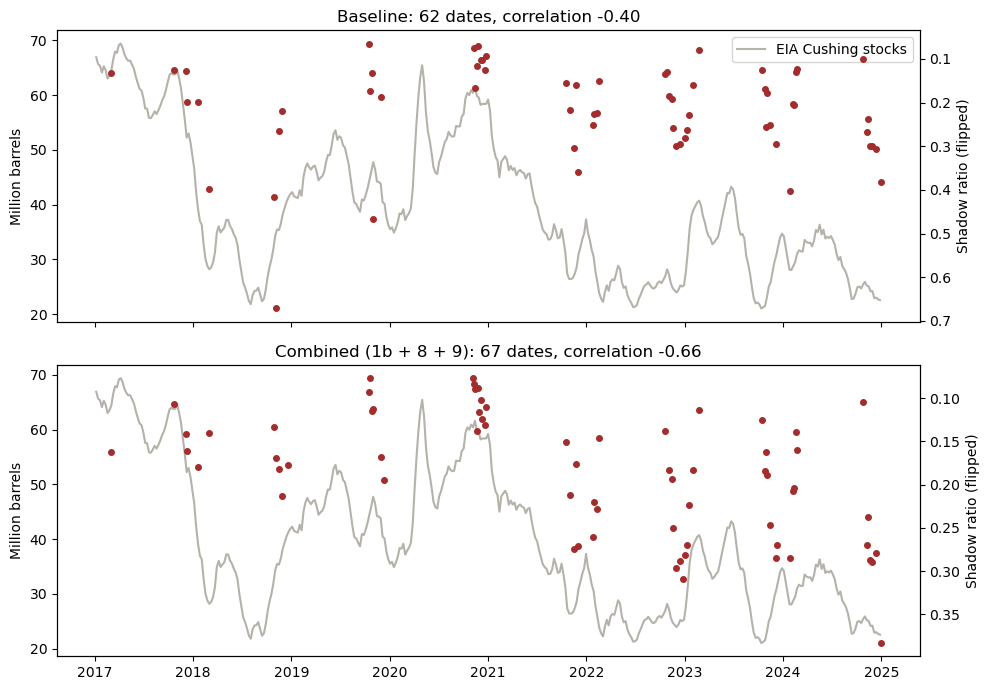

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
versions = {"Baseline": baseline[baseline["ratio"] < CLOUD_RATIO],
            "Combined (1b + 8 + 9)": combined[combined["ratio"] < CLOUD_RATIO]}
for ax, (name, index) in zip(axes, versions.items()):
    ax.plot(cushing["2017":"2024"], color="#B4B2A9", label="EIA Cushing stocks")
    ax.set_ylabel("Million barrels")
    ax2 = ax.twinx()
    ax2.plot(index.index, index["ratio"], "o", color="#A32D2D", markersize=4, label="Shadow ratio")
    ax2.set_ylabel("Shadow ratio (flipped)")
    ax2.invert_yaxis()
    corr = add_stocks(index)[["ratio", "stocks"]].corr().iloc[0, 1]
    ax.set_title(f"{name}: {len(index)} dates, correlation {corr:.2f}")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 9. Conclusions

* **The biggest problem is alignment, not the threshold or the clouds.** Half a pixel moves the ratio by 12%
  to 51% (experiment 6). Lining up each image with the reference image (experiment 9) uses only the pictures
  and raises the correlation from −0.40 to −0.62, with the coefficient unchanged.
* **Use one processing version**, the newest (experiment 8). It is also the more accurate one.
* **Keep images whose tanks are fully visible** (experiment 1b): 5 free dates.
* **Do not** add summer images, the window brightness threshold, or a different tank height.
* **Trend check**: the baseline does not survive in changes (wrong sign), but survives within winters. The
  combined index has the expected sign in changes (z −1.8, not yet significant at 5%) and survives within
  winters about as well as the baseline (z −2.6 against −2.5). So most of the gain is in the levels across
  years, the part a common trend could also produce.
* **Caveat**: experiment 10 was put together after seeing experiments 1 to 9. Each part has a reason that
  does not depend on the correlation, but the combination is not an out-of-sample test.

## 10. Tank map checks

Each check changes only the **set of tanks** of the combined index (1b + 8 + 9), which `Satellite_Group4.ipynb`
now uses. The images, the shift of each image and the cloud dates stay as in the combined index, so every row
uses the same 67 dates. Rules fixed before running:

* **C1, fixed roofs.** A floating roof casts a shadow on itself that changes with the fill; a fixed roof does
  not. We count the dark roof pixels of each tank on each of the 67 dates and drop tanks whose count has a
  standard deviation below **1 pixel**.
* **C2, tank set per year.** From all 415 OpenStreetMap tanks, each year we keep those bright (mean roof
  brightness above 0.6, the baseline's rule) on at least one clear image of that year (tile cloud < 5%,
  sun < 70°, all cached).
* **C3, coverage.** We query OpenStreetMap for a 20 km square around the same centre and count the tanks we
  would gain. Only a count: using them would mean downloading every window again at the larger size.
* **C4, small tanks.** We drop tanks with a radius under 15 m. Cushing's crude tanks are 120 to 194 ft across
  (radius 18 m or more); 15 m leaves a margin for the OpenStreetMap outlines and the 10 m pixels.

In [30]:
by_id = {item["id"]: item for item in items}
clear_images = [by_id[image_id] for image_id in combined["image"]]  # the 67 cloud free dates


def aligned_shift(item):
    """Shift of an image against the reference, or no shift if the match fails (as in experiment 9)."""
    shift = image_shift(load_chip(item))
    return shift if np.abs(shift).max() <= 2 else np.zeros(2)


shifts = {item["id"]: aligned_shift(item) for item in clear_images}


def tank_set_fit(centres, radii, name):
    """Combined index on its 67 cloud free dates, measured with another set of tanks."""
    rows = [measure(item, load_chip(item), centres=centres + shifts[item["id"]], radii=radii)
            for item in clear_images]
    index = add_stocks(to_frame(rows))
    return fit(index, name, dates=len(index)) | {"tanks": len(radii)}


tank_rows = [tank_set_fit(CENTRES, RADII, "Combined index, 398 tanks")]
combined_row = next(row for row in results if row["experiment"] == "10. Combined: 1b + 8 + 9")
print(f"Check: correlation {tank_rows[0]['correlation']:.2f} (combined index: {combined_row['correlation']:.2f})")

Check: correlation -0.66 (combined index: -0.66)


In [31]:
# C1: dark roof pixels of every tank on every date
counts = []
for item in clear_images:
    gray = load_chip(item).mean(axis=2) / 255
    _, _, per_tank = shadow_counts(gray, CENTRES + shifts[item["id"]], RADII, *shadow_geometry(item))
    counts.append(per_tank)
variation = np.array(counts).std(axis=0)  # one number per tank
moving = variation >= 1
print(f"{(~moving).sum()} of {len(moving)} tanks have a dark roof count with a standard deviation below 1 pixel")
tank_rows.append(tank_set_fit(CENTRES[moving], RADII[moving], "C1. Without tanks whose roof shadow never moves"))

112 of 398 tanks have a dark roof count with a standard deviation below 1 pixel


In [32]:
# C2: each year, the tanks that are bright at least once that year
all_centres, all_radii = tank_circles(tanks, reference)  # all 415 tanks
clear_all = [item for item in items if cloud_of(item) < 5 and sun_of(item) < 70]
bright_in = {}
for year in range(2017, 2025):
    images = [item for item in clear_all if date_of(item)[:4] == str(year)]
    brightness = np.array([tank_brightness(load_chip(item).mean(axis=2) / 255, all_centres, all_radii)
                           for item in images])
    bright_in[year] = brightness.max(axis=0) > 0.6
print("Tanks per year:", {year: int(kept.sum()) for year, kept in bright_in.items()})

rows = []
for item in clear_images:
    kept = bright_in[int(date_of(item)[:4])]
    rows.append(measure(item, load_chip(item), centres=all_centres[kept] + shifts[item["id"]],
                        radii=all_radii[kept]))
index = add_stocks(to_frame(rows))
tank_rows.append(fit(index, "C2. Tank set per year", dates=len(index)) | {"tanks": "per year"})

Tanks per year: {2017: 402, 2018: 406, 2019: 408, 2020: 414, 2021: 413, 2022: 414, 2023: 414, 2024: 414}


In [33]:
# C3: how many tanks a 20 km window would add
path = CACHE / "osm_tanks_20km.json"
if not path.exists():
    west, south, east, north = viz.bbox(*CENTRE, 10)  # 20 km square around the same centre
    query = f'[out:json];\nnwr["man_made"="storage_tank"]({south},{west},{north},{east});\nout geom;'
    for server in ("https://overpass-api.de", "https://overpass.kumi.systems"):  # main server, then a mirror
        answer = requests.post(f"{server}/api/interpreter", data={"data": query},
                               headers={"User-Agent": "Bocconi student project"}, timeout=180)
        if answer.ok:
            break
    answer.raise_for_status()
    path.write_text(answer.text)
wide = json.loads(path.read_text())["elements"]
known = {tank["id"] for tank in tanks}
new = [tank for tank in wide if tank["id"] not in known and "geometry" in tank]
_, new_radii = tank_circles(new, reference)
print(f"20 km window: {len(wide)} tanks, {len(new)} more than in our 14 km window; "
      f"{(new_radii * PIXEL_M >= 18).sum()} of them have a radius of 18 m or more")

20 km window: 415 tanks, 0 more than in our 14 km window; 0 of them have a radius of 18 m or more


In [34]:
# C4: drop tanks with a radius under 15 m
large = RADII * PIXEL_M >= 15
print(f"{(~large).sum()} of {len(large)} tanks have a radius under 15 m")
tank_rows.append(tank_set_fit(CENTRES[large], RADII[large], "C4. Without tanks under 15 m radius"))

tank_checks = pd.DataFrame(tank_rows).set_index("experiment")
tank_checks[["tanks", "dates", "correlation", "stocks coef", "HAC z"]].round(
    {"correlation": 2, "stocks coef": 4, "HAC z": 1})

2 of 398 tanks have a radius under 15 m


,tanks,dates,correlation,stocks coef,HAC z
experiment,,,,,
"Combined index, 398 tanks",398,67,-0.66,-0.0037,-6.1
C1. Without tanks whose roof shadow never moves,286,67,-0.67,-0.0048,-6.1
C2. Tank set per year,per year,67,-0.67,-0.0035,-6.8
C4. Without tanks under 15 m radius,396,67,-0.66,-0.0037,-6.1


**Comments – tank map checks**
* **C1:** 112 of the 398 tanks have a roof shadow that barely moves, probably fixed roofs. Without them the
  result is the same (correlation −0.67, z −6.1): these tanks add few dark pixels, so they add little noise.
* **C2:** a tank set per year (402 tanks in 2017, 414 from 2020) gives correlation −0.67 and z −6.8, a little
  stronger than one set from 2018. Tanks built after 2018 do help a bit, but the gain is small.
* **C3:** a 20 km window adds no tank: OpenStreetMap has the same 415 tanks, all inside our 14 km window. (The
  main Overpass server was busy, so this answer came from its mirror, overpass.kumi.systems.)
* **C4:** only 2 of the 398 tanks have a radius under 15 m, so dropping them changes nothing.
* None of the four checks changes our conclusion, so we keep the tank map of `Satellite_Group4.ipynb`.